Splitting dataset-uci into testing and validation set. Validation (unseen) set will only be used for final validation of models
AZ: Following cell need to be placed before Model selection section

In [474]:
validation_set_df = dataset_df.sample(n=30, random_state=RANDOM_STATE)

display(validation_set_df)

validation_set_df.to_csv("dataset_uci_validation_set.csv", index=False)
print("Saved sampled records to dataset_uci_validation_set.csv")

testing_set_df = dataset_df.drop(validation_set_df.index)
testing_set_df.to_csv("dataset_uci_testing_set.csv", index=False)
print("Saved the rest of the records to dataset_uci_testing_set.csv")

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
280,1,53,1,1,0,0,0,1,150,108.4,...,74.0,97.0,13.0,16.0,77.0,0.650,105.200000,16.50,10.90,21.500000
60,0,44,0,0,0,0,0,0,178,86.4,...,39.0,180.0,22.0,40.0,73.0,0.820,116.750000,0.00,15.70,25.150000
297,1,46,1,0,0,0,0,0,165,94.1,...,53.0,122.0,17.0,28.0,68.0,0.830,87.900000,0.00,13.20,15.000000
69,0,59,0,0,0,0,0,0,170,75.9,...,47.0,148.0,27.0,32.0,97.0,0.960,91.050000,0.84,17.30,8.700000
222,1,31,1,0,0,0,0,0,158,100.8,...,48.0,116.0,17.0,18.0,106.0,0.720,114.500000,7.00,12.20,24.000000
204,1,38,0,0,0,0,0,0,175,102.2,...,46.5,175.5,20.5,29.5,91.0,0.725,98.900000,1.63,14.25,26.900000
197,1,31,0,1,0,0,0,0,171,67.0,...,45.0,159.0,60.0,92.0,90.0,0.920,114.000000,3.70,17.00,8.400000
289,1,42,1,0,0,0,0,0,170,79.9,...,42.0,206.0,14.0,17.0,52.0,0.700,110.600000,0.80,13.70,6.300000
94,0,49,1,1,0,1,0,0,158,92.5,...,57.0,82.0,18.0,18.0,92.0,0.630,109.770000,0.78,10.70,21.800000
247,1,56,1,0,0,0,0,0,161,88.6,...,57.0,93.0,15.0,16.0,107.0,0.640,103.600000,0.90,13.90,21.000000


Saved sampled records to dataset_uci_validation_set.csv
Saved the rest of the records to dataset_uci_testing_set.csv


## Logistic Regression

AZ: Describe the model WIP!

The model is trained and evaluated in the following steps:

1. **Features and target:** `Gallstone Status` is the target for the moddel. All other columns in `dataset_df` can be used as predictors/features
2. **Train/test split:** The data is split into training and test sets. we have to stratify the target to balance both sets.
3. TODO: **Scaling:** Features are standardized to minimum ans maximun values of 0 to 1, so the logistic regression return more reliable values.
4. **Model fitting:** A `LogisticRegression` model is fitted on the training data.
5. **Evaluation:** Test-set predictions are scored with accuracy, a confusion matrix, and a classification report (precision, recall, F1).

Install libraries if necessary

In [475]:
# %pip install nbimporter nbformat


Import libraries 

In [528]:
#from src.data_loader import load_data
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler 



Add configurations

In [ ]:
#DATA_PATH = Path("dataset_uci_testing_set.csv")
#DATA_PATH = Path("dataset_uci_cleansed.csv")
DATA_PATH = Path("dataset-uci.csv")
TARGET = "Gallstone Status"
CLASS_NAMES = ["Without gallstones", "With gallstones"]  # 0, 1

PREFERED_FEATURES = [
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]

PREFERED_FEATURES_13=[
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    "Extracellular Fluid/Total Body Water (ECF/TBW)",
    'Hyperlipidemia',
    'Gender',
    'High Density Lipoprotein (HDL)',
    'Aspartat Aminotransferaz (AST)',
    'Creatinine',
    'Alkaline Phosphatase (ALP)',
    'Diabetes Mellitus (DM)'
]


RANDOM_STATE = 14   # one seed for every random operation -> reproducible results
TEST_SIZE = 0.20    # 20 % held out, never touched until the final evaluation
MAX_ITERATIONS = 1000 # maximum number of iterations for the logistic regression solver
CV_SPLITS = 5       # folds per cross-validation round
CV_REPEATS = 10 

Data loader now inside notebook

In [530]:
def load_data(path: Path, target: str = TARGET) -> pd.DataFrame:
    """Load the gallstone dataset and check that it has the expected shape.

    Parameters
    ----------
    path : Path
        Location of the CSV file.
    target : str
        Name of the target column; must be present and binary (0/1).

    Returns
    -------
    pd.DataFrame
        The raw dataset with numeric columns.
    """
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found at {path.resolve()}")

    df = pd.read_csv(path)

    if target not in df.columns:
        raise KeyError(f"Target column '{target}' is missing from the data")
    if not set(df[target].unique()) <= {0, 1}:
        raise ValueError(f"Target column '{target}' must only contain 0 and 1")

    return df


df = load_data(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 319 rows x 39 columns


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [531]:
dataset_df = load_data(DATA_PATH,TARGET)
print(f"Shape: {dataset_df.shape[0]} rows x {dataset_df.shape[1]} columns")
dataset_df.head()

Shape: 319 rows x 39 columns


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [532]:
print(f"Missing values : {dataset_df.isna().sum().sum()}")
print(f"Duplicate rows : {dataset_df.duplicated().sum()}")
print("\nClass balance:")
print(dataset_df[TARGET].value_counts().rename(index=dict(enumerate(CLASS_NAMES))))

Missing values : 0
Duplicate rows : 0

Class balance:
Gallstone Status
Without gallstones    161
With gallstones       158
Name: count, dtype: int64


### Features and target

Use `Gallstone Status` as the binary target variable. Use every other column in `dataset_df` as a predictor, excluding the target to prevent data leakage.

In [556]:
target = TARGET
features = PREFERED_FEATURES
features = PREFERED_FEATURES_13

all_features = dataset_df.columns.tolist()

y = dataset_df[target].astype(int)

X = dataset_df[features]

# All features except the target
#X = dataset_df[all_features].drop(columns=[target])


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)   # splitting into training and testing sets

scaled_logreg_model = make_pipeline( #making pipeline for scaled logistic regression
    StandardScaler(), # scaling the features before applying logistic regression
    LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE),
)
scaled_logreg_model.fit(X_train, y_train) # using the scaled logistic regression model above to fit the training data and testing data
    
scaled_logreg_score = scaled_logreg_model.score(X_test, y_test) # evaluating the scaled logistic regression model on the test data
y_pred_scaled_logreg_model = scaled_logreg_model.predict(X_test) # making predictions with the scaled logistic regression model

print("Scaled Logistic Regression Score:", scaled_logreg_score)
print("Scaled Logistic Regression prediction:", y_pred_scaled_logreg_model)

# 0.765625 7 feature data for random_state = 42
# 0.8125   13 feature data for random_state = 42

# 0.875 7 feature data for random_state = 14 Now with correct scaling and preprocessing
# 0.890625   13 feature data for random_state = 14 Now with correct scaling and preprocessing

Scaled Logistic Regression Score: 0.890625
Scaled Logistic Regression prediction: [0 1 0 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 0 0 1 1 0 1 0 1 1 0
 1 1 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 1 1 0 1 1 1 0 1 0]


Confusion matrix for the logistic regression model


In [557]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred_scaled_logreg_model)
print("Confusion Matrix:")
print(cnf_matrix)

Confusion Matrix:
[[30  2]
 [ 5 27]]


Text(0.5, 427.9555555555555, 'Predicted label')

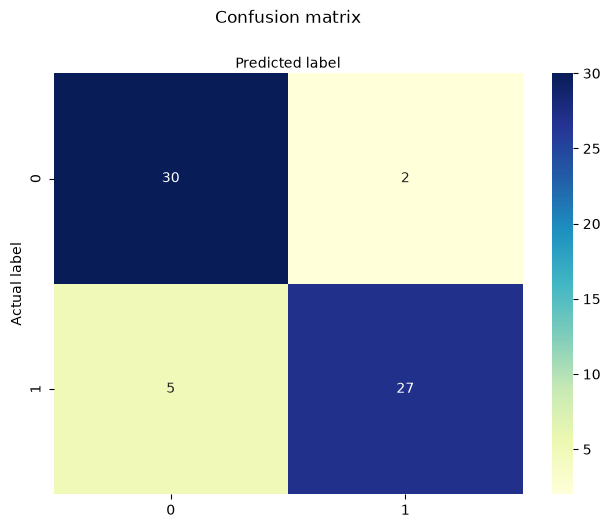

In [558]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [561]:
target_names = ['without Gallstone', 'with Gallstone']
print(classification_report(y_test, y_pred_scaled_logreg_model, target_names=target_names))

                   precision    recall  f1-score   support

without Gallstone       0.86      0.94      0.90        32
   with Gallstone       0.93      0.84      0.89        32

         accuracy                           0.89        64
        macro avg       0.89      0.89      0.89        64
     weighted avg       0.89      0.89      0.89        64



TODO: work more on ROC curve

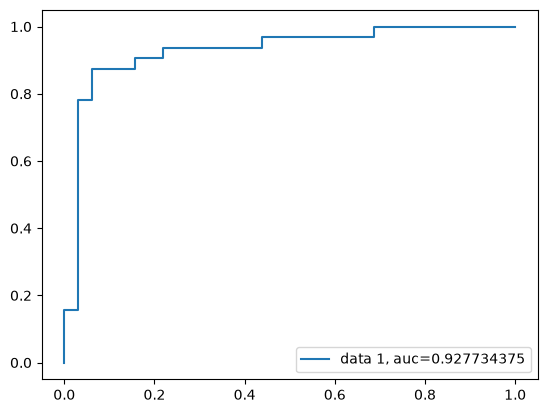

In [563]:
y_pred_proba = scaled_logreg_model.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

TODO: Describe imporovment and tuning (like scaling, etc.)

## References

1. Data camp Understanding Logistic Regression in Python - https://www.datacamp.com/datalab/w/11b0dd9d-49be-429d-992e-45f73b3c23fb#understanding-logistic-regression-in-python 
2. Scikit-learn: LogisticRegression - https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
3. Statistics Calculator - Regression:  https://numiqo.com/statistics-calculator/regression